In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

In [2]:
# load dataset
x_train = np.array([1, 2, 3, 4, 5, 6, 7, 8])
y_train = np.array([50, 54, 58, 65, 67, 72, 76, 81])

print(f"x_train: {x_train}")
print(f"y_train: {y_train}")

x_train: [1 2 3 4 5 6 7 8]
y_train: [50 54 58 65 67 72 76 81]


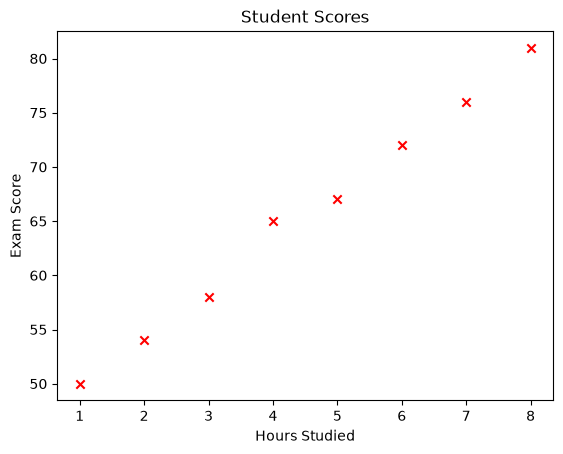

In [3]:
plt.scatter(x_train, y_train, color='red', marker='x')
plt.title("Student Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.show()

In [4]:
# so our goal is to find the straight line that will best fit for our dataset
# as straight line equation is y = w * x + b
# so our main goal is to find the parameters (w,b) that will make our straight line best fit for our data

In [5]:
def model_prediction(x, w, b):
    m = x.shape[0] # no. of training examples
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w * x[i] + b
    return f_wb

In [6]:
# now let's assume we select our parameters (w,b) to 0
w = b = 0
tmp_f_wb = model_prediction(x_train, w, b)

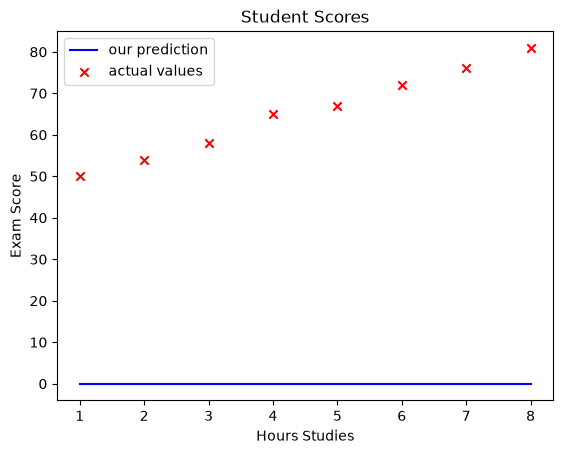

In [7]:
# let's visualize our prediction vs actual values
plt.plot(x_train, tmp_f_wb, color='blue', label='our prediction')
plt.scatter(x_train, y_train, color='red', marker='x', label='actual values')
plt.title("Student Scores")
plt.xlabel("Hours Studies")
plt.ylabel("Exam Score")
plt.legend()
plt.show()

In [8]:
# now as seen above our prediction is way off from the actual values now we have to find correct values for w and b
# for this reason we want to first calculate cost function which tells us numerically how far are we 
# from our original dataset
# and then using this cost function and with the help of gradient descent we can find the values of w and b
# that minimize our cost  function -> means correctly predict the data

In [9]:
def compute_cost(x, y, w, b):
    m = x.shape[0]
    cost_sum = 0
    for i in range(m):
        f_wb = w * x[i] + b
        cost = (f_wb - y[i]) ** 2
        cost_sum += cost
    total_cost = (1/(2*m)) * cost_sum
    return total_cost

In [10]:
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0
    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]
        dj_dw += dj_dw_i
        dj_db += dj_db_i
    dj_db = dj_db / m
    dj_dw = dj_dw / m
    return dj_dw, dj_db

In [11]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, compute_cost, compute_gradient):
    w = w_in
    b = b_in

    j_history = []
    
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(x, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        
        j_history.append(compute_cost(x, y, w, b))

        if i % math.ceil(num_iters/10) == 0:
            print(
                f"Iterations {i:4}: Cost: {j_history[-1]: .3e}",
                f"dj_dw: {dj_dw: .3e}, dj_db: {dj_db: .3e}",
                f"w: {w: .3e}, b: {b: .3e}"
            )

    return w, b, j_history

In [12]:
w = b = 0
tmp_alpha = 0.01
iterations = 5000
w_final, b_final, j_hist = gradient_descent(x_train, y_train, w, b, tmp_alpha, iterations, compute_cost, compute_gradient)
print(f"(w,b) after gradient descent: ({w_final:.2f},{b_final:.2f})")

Iterations    0: Cost:  1.276e+03 dj_dw: -3.174e+02, dj_db: -6.538e+01 w:  3.174e+00, b:  6.538e-01
Iterations  500: Cost:  2.641e+01 dj_dw:  5.666e-01, dj_db: -3.186e+00 w:  7.250e+00, b:  2.957e+01
Iterations 1000: Cost:  3.828e+00 dj_dw:  2.086e-01, dj_db: -1.173e+00 w:  5.460e+00, b:  3.964e+01
Iterations 1500: Cost:  7.667e-01 dj_dw:  7.683e-02, dj_db: -4.319e-01 w:  4.801e+00, b:  4.334e+01
Iterations 2000: Cost:  3.516e-01 dj_dw:  2.829e-02, dj_db: -1.591e-01 w:  4.558e+00, b:  4.470e+01
Iterations 2500: Cost:  2.953e-01 dj_dw:  1.042e-02, dj_db: -5.857e-02 w:  4.469e+00, b:  4.521e+01
Iterations 3000: Cost:  2.877e-01 dj_dw:  3.836e-03, dj_db: -2.156e-02 w:  4.436e+00, b:  4.539e+01
Iterations 3500: Cost:  2.866e-01 dj_dw:  1.412e-03, dj_db: -7.941e-03 w:  4.424e+00, b:  4.546e+01
Iterations 4000: Cost:  2.865e-01 dj_dw:  5.200e-04, dj_db: -2.924e-03 w:  4.419e+00, b:  4.549e+01
Iterations 4500: Cost:  2.865e-01 dj_dw:  1.915e-04, dj_db: -1.077e-03 w:  4.418e+00, b:  4.549e+01


In [13]:
# alright so here's our final values for w and b

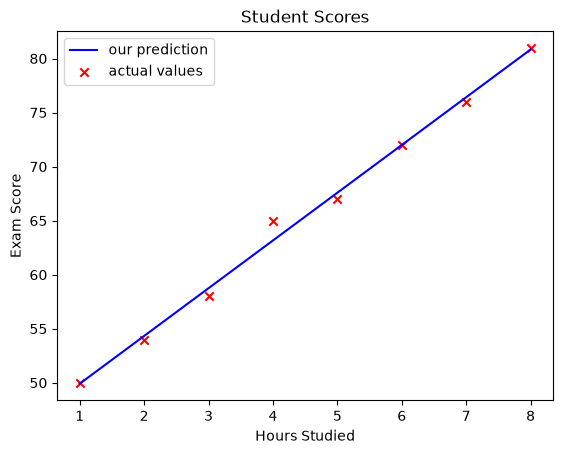

In [14]:
f_wb = model_prediction(x_train, w_final, b_final)
plt.plot(x_train, f_wb, color='blue', label='our prediction')
plt.scatter(x_train, y_train, color='red', marker='x', label='actual values')
plt.title('Student Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.legend()
plt.show()

In [15]:
# so what will be the exam score if our student studies for 6.5 hours 
print(f"Exam score predicted for student studied for 6.5 hours: {(w_final * 6.5 + b_final):.0f}")

Exam score predicted for student studied for 6.5 hours: 74
